# 06 — Would the model work at a new university? Transfer to unseen modules and years

Stage 3 held out whole presentations, but the same *modules* still appeared in training (e.g. train on BBB-2013J, test on BBB-2014J). A new client brings modules with their own design, click norms and assessment schedule. This is the closest OULAD gets to that situation:

1. **Leave one module out:** train on 6 modules, test on the 7th, for each module.
2. **Forward in time:** train on 2013 presentations only, test on 2014, as a real deployment would.
3. **Local history:** for 2014, does including the module's own 2013 run in training help?
4. **Calibration:** do the *probabilities* transfer, and can one completed local run fix them?

All tests use the stage 3 landmark gradient-boosting model, the disengagement-onset target, 10% weekly contact capacity, and landmark weeks 2–12. Differences in recall come with paired bootstrap 95% intervals over presentations.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from eew.experiments import run_stage6, run_stage6_calibration

FIG = pathlib.Path.cwd().parent / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = run_stage6()               # about 2 minutes
cal = run_stage6_calibration()   # about 4 minutes
lomo, fwd, diffs = res["unseen_module"], res["forward_in_time"], res["differences"]
sens = pd.read_csv(pathlib.Path.cwd().parent / "results" / "stage6_shrinkage_sensitivity.csv")
d = diffs.copy(); d["recall difference (pp)"] = [f"{x*100:+.1f} [{lo*100:+.1f}, {hi*100:+.1f}]" for x, lo, hi in zip(d.difference, d.lo, d.hi)]
d[["comparison", "recall difference (pp)"]]

,comparison,recall difference (pp)
0,Module never seen - stage 3 validation (all pr...,"-0.9 [-1.6, -0.2]"
1,2013-trained (incl. own module) - stage 3 vali...,"-0.9 [-1.6, +0.1]"
2,"Own-module history: with - without (2014, modu...","+0.9 [-0.1, +1.8]"


## 1. Ranking: does the weekly contact list still work?

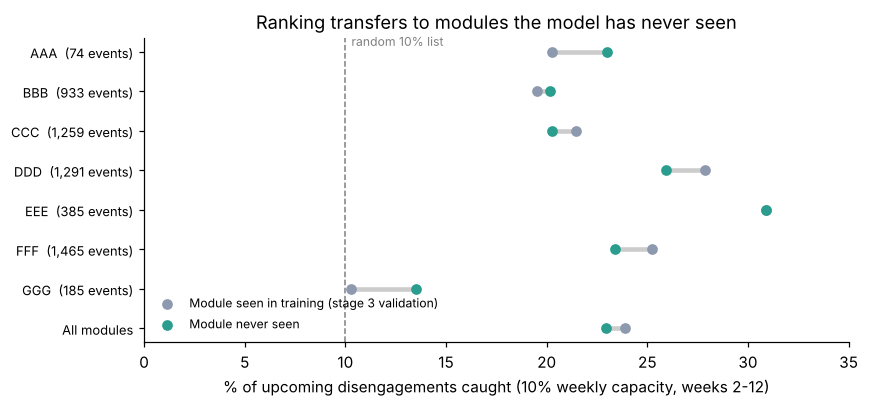

,module,setting,rows,events,recall,precision,auc,calibration_ratio
0,AAA,Stage 3 validation (module seen),4249,74,0.203,0.035,0.651,2.636
1,AAA,Module never seen,4249,74,0.230,0.040,0.630,2.790
2,BBB,Stage 3 validation (module seen),37847,933,0.195,0.048,0.632,1.395
3,BBB,Module never seen,37847,933,0.202,0.050,0.624,1.785
4,CCC,Stage 3 validation (module seen),19837,1259,0.214,0.136,0.669,0.734
5,CCC,Module never seen,19837,1259,0.203,0.128,0.644,0.644
6,DDD,Stage 3 validation (module seen),30666,1291,0.279,0.117,0.720,0.913
7,DDD,Module never seen,30666,1291,0.259,0.109,0.713,0.865
8,EEE,Stage 3 validation (module seen),14990,385,0.309,0.079,0.730,1.224
9,EEE,Module never seen,14990,385,0.309,0.079,0.728,1.308


In [2]:
p = lomo.pivot(index="module", columns="setting", values="recall")
order = [m for m in p.index if m != "All"] + ["All"]
p = p.loc[order]
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(p))[::-1]
a, b = p["Stage 3 validation (module seen)"] * 100, p["Module never seen"] * 100
ax.hlines(y, np.minimum(a, b), np.maximum(a, b), color="#ccc", lw=3)
ax.scatter(a, y, color="#8d99ae", zorder=3, label="Module seen in training (stage 3 validation)")
ax.scatter(b, y, color="#2a9d8f", zorder=3, label="Module never seen")
ax.axvline(10, ls="--", color="grey", lw=1); ax.text(10.3, y[0] + 0.15, "random 10% list", fontsize=8, color="grey")
ax.set_yticks(y, [f"{m}  ({int(n):,} events)" if m != "All" else "All modules" for m, n in
                  zip(p.index, lomo[lomo.setting == "Module never seen"].set_index("module").loc[p.index, "events"])], fontsize=8.5)
ax.set(xlabel="% of upcoming disengagements caught (10% weekly capacity, weeks 2-12)", xlim=(0, 35),
       title="Ranking transfers to modules the model has never seen")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "stage6_unseen_module.png", bbox_inches="tight"); plt.show()
lomo.round(3)

In [3]:
fwd[fwd.module == "All"].round(3)

,module,setting,rows,events,recall,precision,auc,calibration_ratio
21,All,Stage 3 validation,91145,3416,0.241,0.090,0.700,0.935
22,All,"Trained on 2013, incl. own module",91145,3416,0.232,0.086,0.674,0.806
23,All,"Trained on 2013, without own module",91145,3416,0.226,0.084,0.650,0.872


## 2. Probabilities: does calibration transfer?

Pooled calibration hides module-level problems: some modules have far higher or lower disengagement than the model expects from behaviour alone. For each 2014 module with a 2013 run, a **cold-start** model (trained on 2013 data from *other* modules) is compared with the same model **recalibrated using the module's one completed 2013 run**: its odds are scaled by observed ÷ predicted on that run. The correction is **shrunk towards 1 when the run had few events** (weight = events / (events + 100)). Recalibration leaves the ranking within a presentation unchanged, so recall is unaffected.

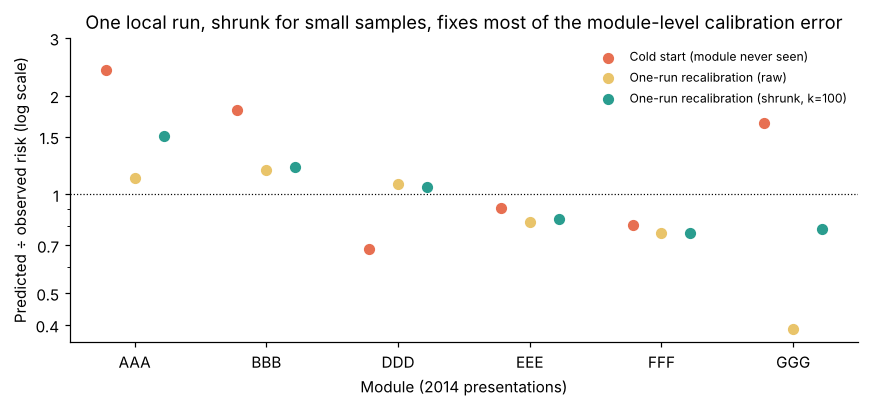

,mean |log ratio|,worst module
setting,,
Cold start (module never seen),0.443,0.870
One-run recalibration (raw),0.295,0.947
"One-run recalibration (shrunk, k=100)",0.224,0.411
Stage 3 validation,0.289,0.862


,shrink_k,mean_abs_log_ratio,max_abs_log_ratio
0,none,0.295,0.947
1,25,0.265,0.670
2,50,0.246,0.481
3,100,0.224,0.411
4,200,0.204,0.541
5,400,0.254,0.660


In [4]:
piv = cal.pivot(index="code_module", columns="setting", values="ratio")
cols = ["Cold start (module never seen)", "One-run recalibration (raw)", "One-run recalibration (shrunk, k=100)"]
colours = ["#e76f51", "#e9c46a", "#2a9d8f"]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(piv))
for i, (c, col) in enumerate(zip(cols, colours)):
    ax.scatter(x + (i - 1) * 0.22, piv[c], color=col, s=40, label=c, zorder=3)
ax.axhline(1, color="black", lw=0.8, ls=":")
ax.set_yscale("log"); ax.yaxis.set_minor_formatter(plt.NullFormatter()); ax.set_yticks([0.4, 0.5, 0.7, 1, 1.5, 2, 3], ["0.4", "0.5", "0.7", "1", "1.5", "2", "3"])
ax.set_xticks(x, piv.index)
ax.set(ylabel="Predicted ÷ observed risk (log scale)", xlabel="Module (2014 presentations)",
       title="One local run, shrunk for small samples, fixes most of the module-level calibration error")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "stage6_calibration.png", bbox_inches="tight"); plt.show()
summary = cal.groupby("setting").abs_log_ratio.agg(["mean", "max"]).rename(columns={"mean": "mean |log ratio|", "max": "worst module"})
display(summary.round(3)); sens.round(3)

## 3. Findings

1. **The weekly contact list transfers to unseen modules with little loss.** On a module it never saw, the model catches 22.9% of upcoming disengagements, against 23.9% when other runs of the module were in training: −0.9 points (interval −1.6 to −0.2), with AUC 0.66 vs 0.70. It stays well above a random 10% list on every module except GGG, where events are rare and the model is weak even with the module seen (AUC 0.51–0.59).
2. **It also transfers forward in time.** Trained on 2013 only and tested on 2014, recall is 23.2% against 24.1% for stage 3 validation (−0.9 points, interval −1.6 to +0.1).
3. **A module's own history adds little to ranking** (+0.9 points, interval −0.1 to +1.8, not significant). A new client could use the weekly ranked list from day one.
4. **Probabilities do not transfer at module level.** For a cold-start model, predicted risk is out by a factor of 0.68 to 2.39 depending on the module (mean |log ratio| 0.44). Even the stage 3 validation model is off by up to 2.4× for some modules, so "calibrated in aggregate" (stage 3) does not mean calibrated per module.
5. **One completed local run fixes most of this, if the correction is shrunk.** Raw recalibration overcorrects modules with very few events (GGG: 1.65 to 0.39). Shrinking the correction by events / (events + 100) cuts the mean error to 0.22 and the worst case to 0.41 (a factor of 1.5), better than the stage 3 validation model (0.29). Results are similar for k between 50 and 200.

**Deployment recommendation for a new institution:** use the ranked weekly list from day one; hide or label probabilities as provisional until each module has one completed run; then recalibrate per module with a shrinkage rule.

**Limitations:** seven modules from one university are a weak proxy for a new institution (same VLE, same data definitions); the shrinkage constant was fixed in advance but tested on only six modules; local recalibration uses a whole completed run, so the earliest possible correction comes one year after launch.